In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import *
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from adcFitter_onsky import AdcFitter

### part 1: finding the response matrix

In [2]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [3]:
disp_x = 0
disp_y = np.linspace(-0.03,0.03,20)
pairs = []

for disp in disp_y:
    psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=disp,num_photons=1E9,ptv=0)
    ADC.set_psf(psf)

    angles = ADC.find_speckle_angles()
    pair = ADC.speckle_pairs(angles)
    pairs.append(pair)

    # if np.any(np.abs(pair) > 10):
    #     break

print(pairs)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


[array([4.51151398, 6.00710596]), array([5.15948523, 6.04309799]), array([4.84720102, 6.03855284]), array([4.19114741, 5.85709244]), array([3.32844308, 5.4620041 ]), array([2.15022718, 4.09774476]), array([2.09621672, 2.10828483]), array([1.03790918, 2.4638433 ]), array([0.17400057, 1.99753279]), array([-0.77950697,  0.11196603]), array([0.81129075, 0.25682526]), array([ 0.20326393, -2.00455078]), array([-0.7844259 , -2.50164667]), array([-2.12627614, -1.84823913]), array([-2.12741701, -4.0570956 ]), array([-3.34408471, -5.48314731]), array([-4.15516086, -5.81826548]), array([-4.8116947 , -6.01121477]), array([-4.10015036, -6.07636107]), array([-4.55533399, -6.0838115 ])]


In [4]:
pairs = np.zeros((50,2))
dispersions = np.linspace(-0.05,0.05,50)

for i,dispersion in enumerate(dispersions):
    psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=dispersion,num_photons=1E9,ptv=0)
    ADC.set_psf(psf)
    angles = ADC.find_speckle_angles()
    pointing_pair = ADC.speckle_pairs(angles)
    pairs[i,] = pointing_pair

print(pairs)

[[ 4.62687283  4.57263909]
 [ 4.6523204   3.86576166]
 [ 4.68045344  3.12790196]
 [ 4.76640156  6.18034932]
 [ 4.74666023  5.9066408 ]
 [ 4.76301453  5.68083198]
 [ 4.75440556  4.83022415]
 [ 4.76968866  6.35122709]
 [ 4.72223374  6.25499697]
 [ 4.62572276  6.24990864]
 [ 4.49613623  6.00526133]
 [ 5.24978583  6.13406304]
 [ 5.14522572  5.95970206]
 [ 4.76511751  5.91689496]
 [ 4.32552121  5.96549069]
 [ 3.9153513   5.78434817]
 [ 3.33869373  5.47680958]
 [ 2.5871866   4.35487128]
 [ 1.65337648  3.41915407]
 [ 0.86418215  1.96496018]
 [ 1.29649694  0.56150326]
 [ 0.91154326  1.41062799]
 [ 0.06365796  2.17005901]
 [-0.33720872  1.01452843]
 [ 0.63830609 -0.67444685]
 [-0.29896644  0.67132691]
 [ 0.41419354 -0.97186731]
 [ 0.02655611 -2.16774248]
 [-0.59289955 -1.37368087]
 [-1.15132272 -0.28662351]
 [-0.89837111 -1.9552141 ]
 [-1.66742191 -3.59085438]
 [-2.61696325 -4.43130053]
 [-3.34219638 -5.47432675]
 [-3.96910588 -5.75552219]
 [-4.35450193 -5.84470247]
 [-4.76681011 -5.96272811]
 

[[ 4.62687283  4.57263909]
 [ 4.6523204   3.86576166]
 [ 4.68045344  3.12790196]
 [ 4.76640156  6.18034932]
 [ 4.74666023  5.9066408 ]
 [ 4.76301453  5.68083198]
 [ 4.75440556  4.83022415]
 [ 4.76968866  6.35122709]
 [ 4.72223374  6.25499697]
 [ 4.62572276  6.24990864]
 [ 4.49613623  6.00526133]
 [ 5.24978583  6.13406304]
 [ 5.14522572  5.95970206]
 [ 4.76511751  5.91689496]
 [ 4.32552121  5.96549069]
 [ 3.9153513   5.78434817]
 [ 3.33869373  5.47680958]
 [ 2.5871866   4.35487128]
 [ 1.65337648  3.41915407]
 [ 0.86418215  1.96496018]
 [ 1.29649694  0.56150326]
 [ 0.91154326  1.41062799]
 [ 0.06365796  2.17005901]
 [-0.33720872  1.01452843]
 [ 0.63830609 -0.67444685]
 [-0.29896644  0.67132691]
 [ 0.41419354 -0.97186731]
 [ 0.02655611 -2.16774248]
 [-0.59289955 -1.37368087]
 [-1.15132272 -0.28662351]
 [-0.89837111 -1.9552141 ]
 [-1.66742191 -3.59085438]
 [-2.61696325 -4.43130053]
 [-3.34219638 -5.47432675]
 [-3.96910588 -5.75552219]
 [-4.35450193 -5.84470247]
 [-4.76681011 -5.96272811]
 

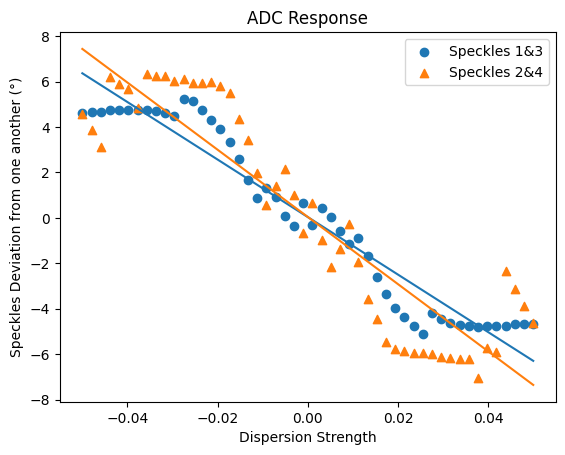

In [5]:
#pairs = np.matrix(pairs).T
print(pairs)
print(dispersions)
#print(pairs)

a1 = np.zeros(2)
b1 = np.zeros(2)

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    b1[j] , a1[j] = np.polyfit(dispersions,pairs[:,j],deg=1)
    plt.scatter(dispersions, pairs[:,j], label=labels[j],marker=markers[j])
    plt.plot(dispersions, a1[j] + b1[j] * dispersions)
    print(f'Slope of {labels[j]} Response: {b1[j]}')

plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckles Deviation from one another (°)')
plt.legend()
plt.show()

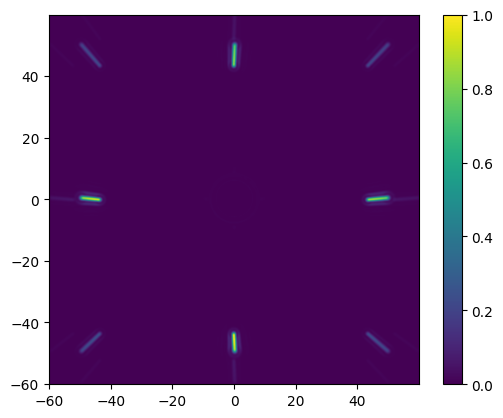

In [6]:
wavelength = 764E-9
bw = 120E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 0
grating_freq = 40

ADC = AdcFitter(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=60,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)
disp_x = np.random.rand() * 0.05
disp_y = np.random.rand() * 0.05

psf = PsfGen.psf(magnitude_x=disp_x,magnitude_y=disp_y)
ADC.set_psf(psf)

imshow_field(ADC.psf)
plt.colorbar()

In [7]:
#let's look at the fit visually
def visualize_fit(image):
    speckle_angles = np.zeros(4)
    sig_x = [1,3.5,1,3.5]
    sig_y = [3.5,1,3.5,1]
    fit_image = image - image

    for i in range(4):
        img = ADC.find_speckle(ADC.psf,i)
        ADC.current_speckle = i
        ADC.set_measurement(img)

        sigma_x = .5#sig_x[i]
        sigma_y = .5#sig_y[i]
        orientation = 0 #np.radians(30)

        # orientation = ADC.estimate_angle()
        # if ADC.current_speckle == 0 or ADC.current_speckle ==2:
        #     orientation = np.pi/2 - orientation
        # elif ADC.current_speckle == 1 or ADC.current_speckle == 3:
        #     orientation = -orientation

        amplitude = ADC.data.max()
        centroid = ADC.estimate_centroid()
        mu_x = centroid[0]
        mu_y = centroid[1]
        background = 0

        theta_est = np.array([amplitude, mu_x, mu_y, sigma_x, sigma_y, orientation, background])
        fit = ADC.fit(theta_est) 
        theta = fit.x
        speckle_angles[i] = np.degrees(theta[5])
        fit_image = fit_image + ADC.satellite_spot(*theta)(image.grid)
        print(f'initial orientation value {orientation} fitted value {theta[5]}')
        #print(f'aspect ratio:{np.abs(theta[3]/theta[4])}')

    ADC.current_speckle = None
    speckle_angles = np.array(speckle_angles).T

    print(f'aspect ratio:{np.abs(theta[3]/theta[4])}')
    print(f'speckle angles:{speckle_angles}')
    return fit_image

initial orientation value 0 fitted value -0.006021142028716918
initial orientation value 0 fitted value -0.006621325352453215
initial orientation value 0 fitted value -0.007936495260016054
initial orientation value 0 fitted value -0.008096080883188916
aspect ratio:4.420368623112903
speckle angles:[-0.34498603 -0.379374   -0.45472768 -0.46387127]


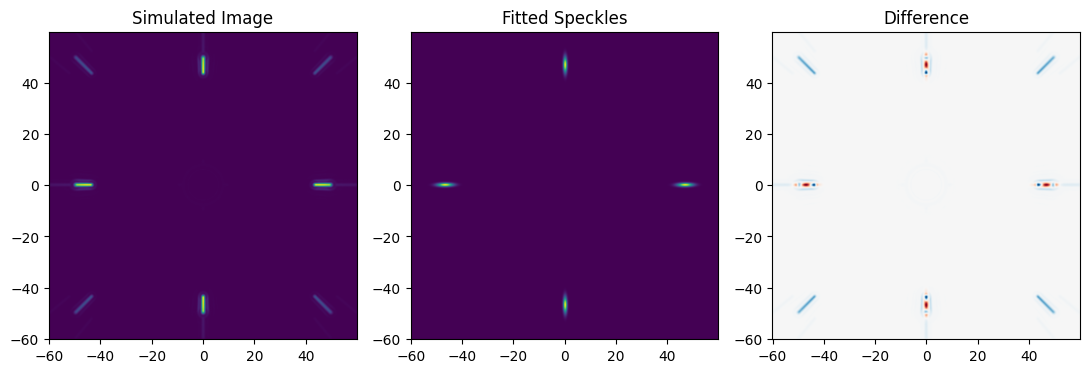

In [8]:
psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=0,num_photons=1E8,ptv=0,diam=1)
ADC.set_psf(psf)

fitted = visualize_fit(ADC.psf)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(ADC.psf)
plt.title('Simulated Image')
plt.subplot(1,3,2)
imshow_field(fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(ADC.psf - fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

In [9]:
#same thing,but with a real lab image
ADC.set_psf(img)
real_fitted = visualize_fit(img)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(img)
plt.title('Lab Image')
plt.subplot(1,3,2)
imshow_field(real_fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(img - real_fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

NameError: name 'img' is not defined

In [ ]:
#now let's see if there's bias in the simulated images if we use zero dispersion and introduce some poisson noise:
pairs = []
num_photons = 1E6

for i in range(20):
    psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=0,num_photons=num_photons,ptv=0.3)
    ADC.set_psf(psf)

    angles = ADC.find_speckle_angles()
    pair = ADC.speckle_pairs(angles)
    pairs.append(pair)

    if np.any(np.abs(pair) > 10):
        break

pairs = np.matrix(pairs)

3.5442218846142435
2.993742229902919
3.3624566770930504
3.098625798620488
3.1348488993954695
3.3220257511001705
3.263450386628143
3.2834483907223904
2.856368525597675
3.488907685360517
3.6996790344921116
3.4275504523422864
3.4683975984250592
3.220436927060169
2.9976797525205376
3.2719259085054877
3.733851146933205
3.38142092894841
3.189888893669072
3.649736392545316


In [ ]:
print(angles)
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

[28.82679519 28.7897356  27.78644543 27.80912829]
mean offset: [[ 0.14743068 -0.36826764]]°
sd of pointing offsets: [[1.63557674 1.70661045]]°


mean offset: [[ 0.44470891 -0.33722558]]°
sd of pointing offsets: [[0.7873589  1.36843292]]°


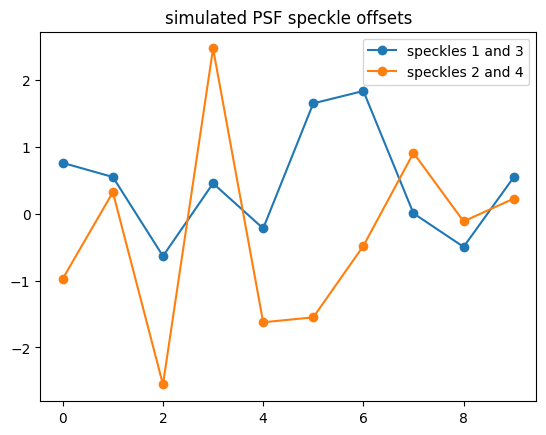

In [ ]:
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

plt.plot(pairs[0:80,0],'o-',label='speckles 1 and 3')
plt.plot(pairs[:,1],'o-',label='speckles 2 and 4')
plt.title('simulated PSF speckle offsets')
plt.legend()
plt.show()

### exact recreation of the response procedure from simulated_pairs_response.ipynb

In [ ]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

In [ ]:
adc_diff_angles = np.linspace(0,4,15)
ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:37: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


[ 22.87697298 -10.02396511]


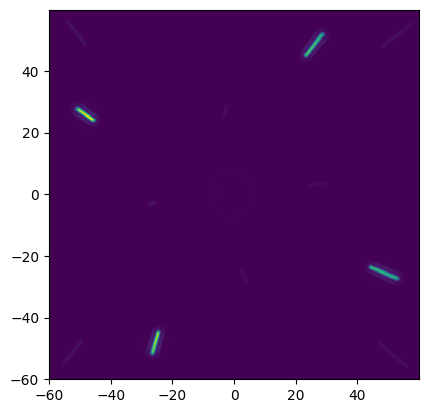

In [ ]:
#img = ADC.simulate_noisy_dispersion(0.1,0.05,1E9)
img = PsfGen.noisy_turbulent_psf(magnitude_x=0.1,magnitude_y=0,num_photons=1E9,ptv=0)
imshow_field(img)
ADC.set_psf(img)
angles = ADC.find_speckle_angles()
pointing_pairs = ADC.speckle_pairs(angles)
print(pointing_pairs)

In [ ]:
'''delta difference angles'''
diff_pointing_pairs = np.zeros((50,2))
dispersions = np.linspace(-0.1,0.1,50)

for i,dispersion in enumerate(dispersions):
    #img = ADC.simulate_noisy_dispersion(dispersion,0,1E9)
    img = PsfGen.noisy_turbulent_psf(magnitude_x=dispersion,magnitude_y=0,num_photons=1E9,ptv=0)
    ADC.set_psf(img)
    angles = ADC.find_speckle_angles()
    pointing_pair = ADC.speckle_pairs(angles)
    diff_pointing_pairs[i,] = pointing_pair

print(diff_pointing_pairs)

[[-22.8919007   10.06772395]
 [-20.98848964   9.23229572]
 [-19.5682532    7.96489146]
 [-18.31059254   7.13239846]
 [-17.13404112   6.47216852]
 [-16.21090862   5.45038531]
 [-14.85654      4.48084961]
 [-13.49114136   3.38558219]
 [-11.90806098   2.33582625]
 [-10.02011547   4.93396233]
 [ -7.67537279   4.7958224 ]
 [ -6.37367567   4.69024079]
 [ -4.98352593   4.64994733]
 [ -3.54431403   4.59773453]
 [ -5.98935733   4.70671924]
 [ -5.69104616   4.74328382]
 [ -6.0413767    4.76810447]
 [ -5.94800284   4.68312053]
 [ -5.85077142   5.15286967]
 [ -5.81656337   4.65515396]
 [ -5.54952749   3.6874845 ]
 [ -4.10727284   2.21649812]
 [ -1.3262307    0.27961914]
 [ -2.65834562   0.43189216]
 [ -0.23366503  -0.98616128]
 [  0.17081819   0.95254891]
 [  2.65639332  -0.25708772]
 [  1.4350685   -1.96005054]
 [  3.91680037  -2.20351637]
 [  5.59668926  -3.70468811]
 [  5.80008402  -4.53782559]
 [  6.01943913  -5.16495637]
 [  6.00334526  -4.64472651]
 [  6.33826903  -4.69220932]
 [  7.12573752

Slope of Speckles 1&3 Response: 191.31780748048953
Slope of Speckles 2&4 Response: -84.25557918091783


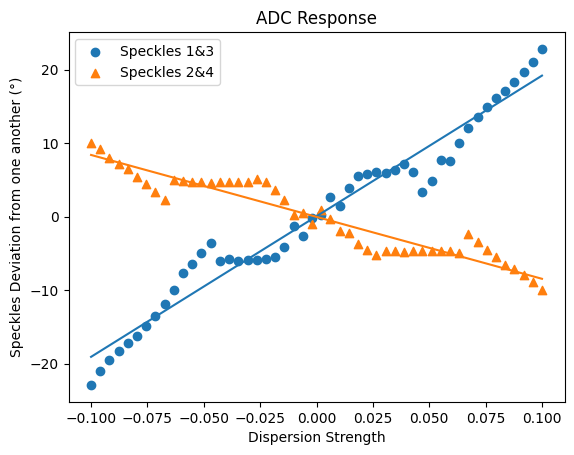

In [ ]:
a1 = np.zeros(4)
b1 = np.zeros(4)

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

for j in range(2):
    b1[j] , a1[j] = np.polyfit(dispersions,diff_pointing_pairs[:,j],deg=1)
    plt.scatter(dispersions, diff_pointing_pairs[:,j], label=labels[j],marker=markers[j])
    plt.plot(dispersions, a1[j] + b1[j] * dispersions)
    print(f'Slope of {labels[j]} Response: {b1[j]}')

plt.title('ADC Response')
plt.xlabel('Dispersion Strength')
plt.ylabel('Speckles Deviation from one another (°)')
plt.legend()
plt.show()